In [1]:

import pandas as pd
from pathlib import Path

data_folder = Path("../data")
csv_files = list(data_folder.glob("*.csv"))

print("CSV files found:")
for file in csv_files:
    print(file.name)


CSV files found:
spc_fsm_api.csv


In [2]:

df = pd.read_csv(csv_files[0], low_memory=False)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Rows and columns: (95323, 17)


,time_period,time_identifier,geographic_level,country_code,country_name,region_name,region_code,old_la_code,new_la_code,la_name,pcon_code,pcon_name,phase_type_grouping,fsm_eligibility,fsm_breakdown,pupil_count,pupil_percent
0,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,FSM eligible,FSM eligible - infants taking free school meal...,5,1.40056
1,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,FSM eligible,All pupils,274,76.75070
2,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,FSM eligible,FSM eligible - performance table metric,274,76.75070
3,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,Total,All pupils - performance table metric,357,100.00000
4,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,Total,All pupils,357,100.00000


In [3]:

df.columns.tolist()


['time_period',
 'time_identifier',
 'geographic_level',
 'country_code',
 'country_name',
 'region_name',
 'region_code',
 'old_la_code',
 'new_la_code',
 'la_name',
 'pcon_code',
 'pcon_name',
 'phase_type_grouping',
 'fsm_eligibility',
 'fsm_breakdown',
 'pupil_count',
 'pupil_percent']

In [4]:
#Count missing values in each column
missing_values=df.isna().sum()
print(missing_values)

time_period                0
time_identifier            0
geographic_level           0
country_code               0
country_name               0
region_name            31383
region_code            31383
old_la_code            35635
new_la_code            35635
la_name                35635
pcon_code              64416
pcon_name              64416
phase_type_grouping        0
fsm_eligibility            0
fsm_breakdown              0
pupil_count                0
pupil_percent              0
dtype: int64


In [5]:
#Count completely identical rows
duplicates=df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [7]:
#Identify geographical categories
df['geographic_level'].value_counts()

geographic_level
Local authority               59688
Parliamentary constituency    30907
Regional                       4252
National                        476
Name: count, dtype: int64

In [8]:

# Calculate the percentage of missing values in each column

missing_percent = df.isna().mean() * 100

print(missing_percent.round(2))


time_period             0.00
time_identifier         0.00
geographic_level        0.00
country_code            0.00
country_name            0.00
region_name            32.92
region_code            32.92
old_la_code            37.38
new_la_code            37.38
la_name                37.38
pcon_code              67.58
pcon_name              67.58
phase_type_grouping     0.00
fsm_eligibility         0.00
fsm_breakdown           0.00
pupil_count             0.00
pupil_percent           0.00
dtype: float64


In [9]:
#Count records by geographical level
df['geographic_level'].value_counts()

geographic_level
Local authority               59688
Parliamentary constituency    30907
Regional                       4252
National                        476
Name: count, dtype: int64

In [10]:
#Identify free school meal eligibility categories
print(df['fsm_eligibility'].value_counts(dropna=False))
print(df["fsm_breakdown"].value_counts(dropna=False))

fsm_eligibility
FSM eligible    63783
Total           31540
Name: count, dtype: int64
fsm_breakdown
All pupils                                                       31540
FSM eligible - infants taking free school meal on census date    15770
FSM eligible - performance table metric                          15770
All pupils - performance table metric                            15770
FSM eligible - taking free school meal on census date            14563
FSM eligible - eligible since March 23rd 2020                     1910
Name: count, dtype: int64


The dataset contains repeated local authority names because the records are organised by multiple dimensions, including academic year, school phase and free school meal eligibility. These records should not automatically be treated as duplicates.

In [11]:
#Check how python stores the academic year
print(df["time_period"].dtype)
#See the available academic years
print(df["time_period"].unique())

int64
[202526 202425 202324 202223 202122 202021 201920 201819 201718 201617
 201516]


In [14]:

# Select the latest academic year and local authorities

df_2025 = df[
    (df["time_period"].astype(str) == "202526") &
    (df["geographic_level"] == "Local authority")
].copy()

print("Original rows:", len(df))
print("Filtered rows:", len(df_2025))

df_2025.head()


Original rows: 95323
Filtered rows: 5189


,time_period,time_identifier,geographic_level,country_code,country_name,region_name,region_code,old_la_code,new_la_code,la_name,pcon_code,pcon_name,phase_type_grouping,fsm_eligibility,fsm_breakdown,pupil_count,pupil_percent
0,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,FSM eligible,FSM eligible - infants taking free school meal...,5,1.40056
1,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,FSM eligible,All pupils,274,76.75070
2,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,FSM eligible,FSM eligible - performance table metric,274,76.75070
3,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,Total,All pupils - performance table metric,357,100.00000
4,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded AP school,Total,All pupils,357,100.00000


In [15]:
df_2025["phase_type_grouping"].value_counts()

phase_type_grouping
Total                            918
State-funded primary             912
State-funded secondary           912
State-funded special school      900
State-funded AP school           707
State-funded nursery             606
Non-maintained special school    234
Name: count, dtype: int64

In [16]:

df_2025.groupby(
    ["fsm_eligibility", "fsm_breakdown"],
    dropna=False
).size()


fsm_eligibility  fsm_breakdown                                                
FSM eligible     All pupils                                                       888
                 FSM eligible - infants taking free school meal on census date    888
                 FSM eligible - performance table metric                          888
                 FSM eligible - taking free school meal on census date            749
Total            All pupils                                                       888
                 All pupils - performance table metric                            888
dtype: int64

In [17]:
#Select state-funded primary schools
df_primary = df_2025[
    (df_2025["phase_type_grouping"] == "State-funded primary")
].copy()
print("Primary school records:", len(df_primary))
df_primary.head()

Primary school records: 912


,time_period,time_identifier,geographic_level,country_code,country_name,region_name,region_code,old_la_code,new_la_code,la_name,pcon_code,pcon_name,phase_type_grouping,fsm_eligibility,fsm_breakdown,pupil_count,pupil_percent
11,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded primary,FSM eligible,FSM eligible - taking free school meal on cens...,13809,23.492285
12,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded primary,FSM eligible,FSM eligible - infants taking free school meal...,20000,34.024600
13,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded primary,FSM eligible,All pupils,17387,29.579286
14,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded primary,FSM eligible,FSM eligible - performance table metric,17023,29.920554
15,202526,Academic year,Local authority,E92000001,England,East Midlands,E12000004,830.0,E10000007,Derbyshire,NaN,NaN,State-funded primary,Total,All pupils - performance table metric,56894,100.000000


In [18]:
#Count the different FSM measure combinations
df_primary.groupby(
    ["fsm_eligibility", "fsm_breakdown"],
    dropna=False
).size()

fsm_eligibility  fsm_breakdown                                                
FSM eligible     All pupils                                                       152
                 FSM eligible - infants taking free school meal on census date    152
                 FSM eligible - performance table metric                          152
                 FSM eligible - taking free school meal on census date            152
Total            All pupils                                                       152
                 All pupils - performance table metric                            152
dtype: int64

In [19]:

# Check how percentages are stored

print(df_primary["pupil_percent"].dtype)

print(df_primary[
    ["la_name", "fsm_eligibility",
     "fsm_breakdown", "pupil_percent"]
].head(12))

float64
       la_name fsm_eligibility  \
11  Derbyshire    FSM eligible   
12  Derbyshire    FSM eligible   
13  Derbyshire    FSM eligible   
14  Derbyshire    FSM eligible   
15  Derbyshire           Total   
16  Derbyshire           Total   
52       Derby    FSM eligible   
53       Derby    FSM eligible   
54       Derby    FSM eligible   
55       Derby    FSM eligible   
56       Derby           Total   
57       Derby           Total   

                                        fsm_breakdown  pupil_percent  
11  FSM eligible - taking free school meal on cens...      23.492285  
12  FSM eligible - infants taking free school meal...      34.024600  
13                                         All pupils      29.579286  
14            FSM eligible - performance table metric      29.920554  
15              All pupils - performance table metric     100.000000  
16                                         All pupils     100.000000  
52  FSM eligible - taking free school meal on cens..

In [20]:

# Filter to FSM eligibility among all pupils

df_fsm = df_primary[
    (df_primary["fsm_eligibility"] == "FSM eligible") &
    (df_primary["fsm_breakdown"] == "All pupils")
].copy()

print("Records selected:", len(df_fsm))

df_fsm[
    ["la_name", "fsm_eligibility",
     "fsm_breakdown", "pupil_percent"]
].head(10)


Records selected: 152


,la_name,fsm_eligibility,fsm_breakdown,pupil_percent
13,Derbyshire,FSM eligible,All pupils,29.579286
54,Derby,FSM eligible,All pupils,36.668728
89,Leicestershire,FSM eligible,All pupils,16.300470
118,Leicester,FSM eligible,All pupils,25.218337
142,Rutland,FSM eligible,All pupils,11.547619
166,Nottinghamshire,FSM eligible,All pupils,22.524881
207,Nottingham,FSM eligible,All pupils,35.958526
242,Lincolnshire,FSM eligible,All pupils,28.923066
272,North Northamptonshire,FSM eligible,All pupils,19.357537
307,West Northamptonshire,FSM eligible,All pupils,15.835310


In [21]:

# Count how many times each local authority appears

df_fsm["la_name"].value_counts().head(10)


la_name
Derbyshire                1
Derby                     1
Leicestershire            1
Leicester                 1
Rutland                   1
Nottinghamshire           1
Nottingham                1
Lincolnshire              1
North Northamptonshire    1
West Northamptonshire     1
Name: count, dtype: int64

In [22]:

print("Total records:", len(df_fsm))

print(
    "Unique local authorities:",
    df_fsm["new_la_code"].nunique()
)

print(
    "Missing percentages:",
    df_fsm["pupil_percent"].isna().sum()
)


Total records: 152
Unique local authorities: 152
Missing percentages: 0


In [23]:

# Keep only the variables needed for analysis

df_clean = df_fsm[
    ["new_la_code", "la_name",
     "region_name", "pupil_count",
     "pupil_percent"]
].copy()

# Give columns clearer names
df_clean = df_clean.rename(columns={
    "pupil_count": "fsm_eligible_pupils",
    "pupil_percent": "fsm_eligibility_percent"
})

# Sort by eligibility percentage
df_clean = df_clean.sort_values(
    "fsm_eligibility_percent",
    ascending=False
)

df_clean.head(10)


,new_la_code,la_name,region_name,fsm_eligible_pupils,fsm_eligibility_percent
2496,E08000003,Manchester,North West,24747,47.976968
4214,E08000025,Birmingham,West Midlands,49541,47.056868
885,E09000019,Islington,London,5765,45.954564
739,E09000007,Camden,London,4451,45.376695
809,E09000012,Hackney,London,7207,43.290485
4413,E08000031,Wolverhampton,West Midlands,11093,42.202777
1865,E08000021,Newcastle upon Tyne,North East,9448,41.942644
4483,E06000021,Stoke-on-Trent,West Midlands,10087,41.529087
1060,E09000030,Tower Hamlets,London,9466,40.522260
2034,E06000002,Middlesbrough,North East,6085,40.077719


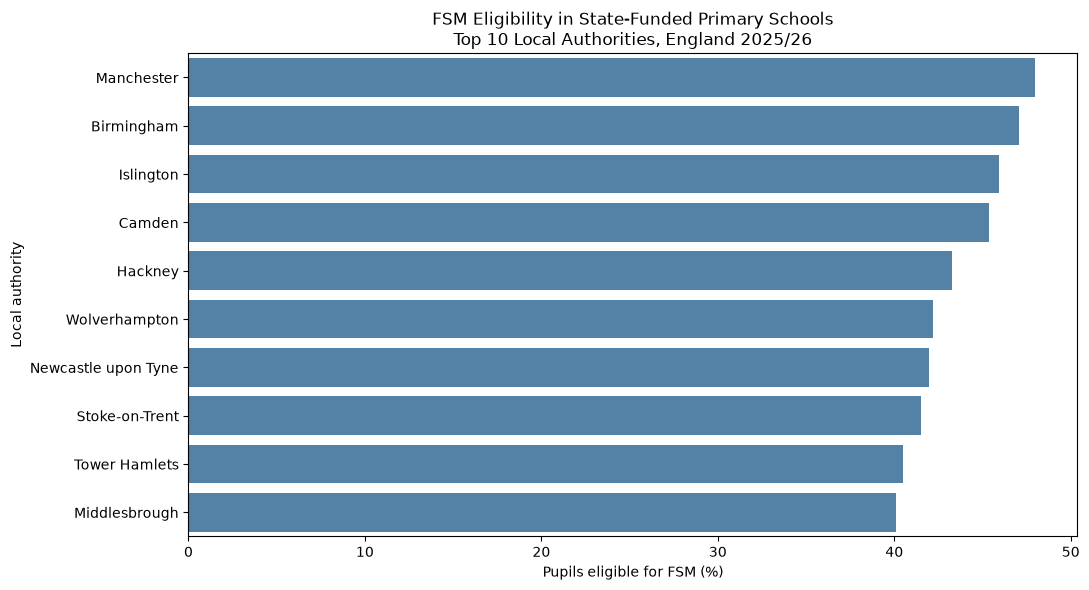

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select the 10 highest percentages
top10 = df_clean.head(10)

# Create the chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top10,
    x="fsm_eligibility_percent",
    y="la_name",
    color="steelblue"
)

plt.title(
    "FSM Eligibility in State-Funded Primary Schools\n"
    "Top 10 Local Authorities, England 2025/26"
)

plt.xlabel("Pupils eligible for FSM (%)")
plt.ylabel("Local authority")

plt.tight_layout()
plt.show()


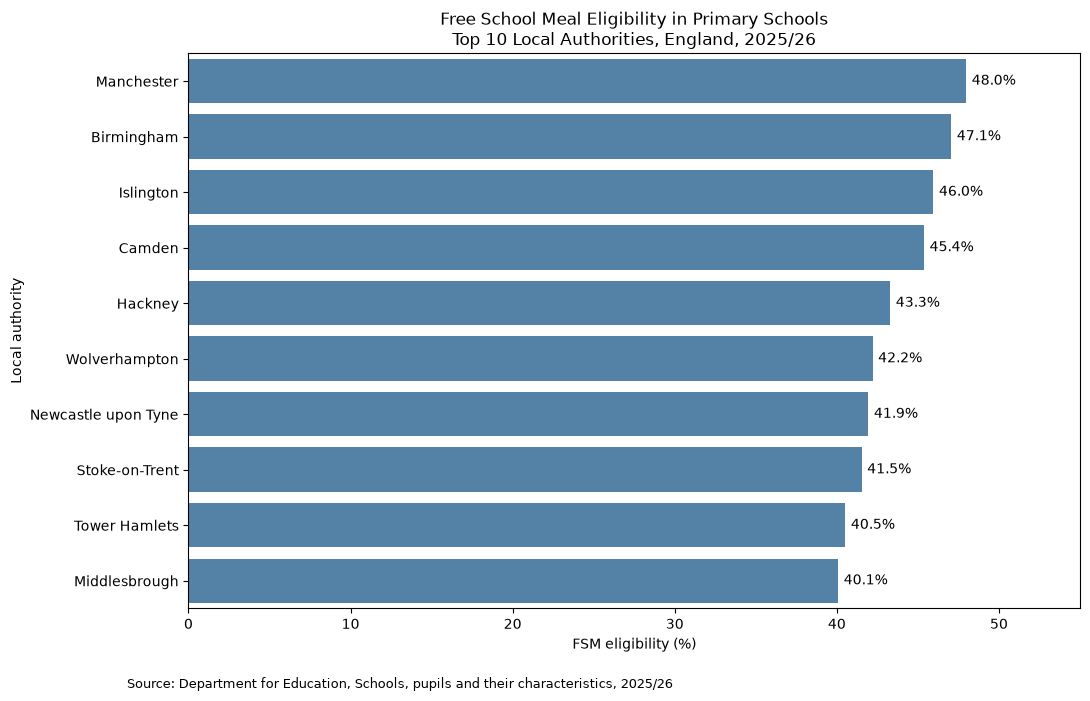

In [28]:


import matplotlib.pyplot as plt
import seaborn as sns

top10 = df_clean.head(10)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top10,
    x="fsm_eligibility_percent",
    y="la_name",
    color="steelblue",
    ax=ax
)

# Add percentage labels to the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

ax.set_xlim(0, 55)

ax.set_title(
    "Free School Meal Eligibility in Primary Schools\n"
    "Top 10 Local Authorities, England, 2025/26"
)

ax.set_xlabel("FSM eligibility (%)")
ax.set_ylabel("Local authority")

fig.text(
    0.12, 0.01,
    "Source: Department for Education, Schools, pupils and their characteristics, 2025/26",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    "../outputs/top10_fsm_eligibility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



What does the chart tell us about differences in FSM eligibility between local authorities, and what can't we conclude from these data alone?

In [26]:

df_clean.to_csv(
    "../outputs/fsm_primary_2025_26_clean.csv",
    index=False
)

print("Clean dataset saved successfully!")


Clean dataset saved successfully!


In [27]:
df_clean.to_csv(
    "../outputs/fsm_primary_2025_26_clean.csv",
    index=False
)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


### Finding 1: Exploring Geographical Inequalities in Free School Meal Eligibility: An Analysis of State-Funded Primary Schools in England (2025/26)

Analysis of Department for Education data for the 2025/26 academic year identified variation in FSM eligibility among pupils attending state-funded primary schools across 152 English local authorities.

Manchester recorded the highest percentage (47.98%), followed by Birmingham (47.06%) and Islington (45.95%).

These findings indicate geographical differences in FSM eligibility. However, eligibility should not be interpreted as a direct or comprehensive measure of child poverty. Further research would be required to investigate potential explanations for these differences.

**Source:** Department for Education (2026), *Schools, pupils and their characteristics: 2025/26*.